# 오늘 실습 내용 요약:

- SimpleRNN: 가장 기본적인 순환 신경망  
- LSTM / GRU: 장기 기억 능력을 개선한 모델  
- Deep RNN: 층을 깊게 쌓아 복잡한 패턴 학습
- Bidirectional RNN: 과거와 미래를 모두 보고 결측값 채우기 (Imputation)
- Many-to-Many: 입력과 출력이 모두 시퀀스인 경우 (시계열 변환)
- Many-to-One (NLP): 영화 리뷰 텍스트를 분석해 감성(긍정/부정) 분류

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.optimizers import RMSprop

- import numpy: 데이터 생성 및 행렬 연산
- import matplotlib: 데이터와 예측 결과를 그래프로 그리기 위함
- Sequential: 신경망 층(Layer)을 순서대로 쌓아 모델을 만드는 컨테이너
- SimpleRNN: 시계열 데이터를 처리하는 기본 RNN 층
- Dense: 최종 예측값 출력을 위한 완전 연결(Fully Connected) 층
- RMSprop: 가중치를 업데이트하는 최적화 알고리즘(Optimizer)

# 데이터 생성

In [2]:
np.random.seed(42) # 실행할 때마다 동일한 난수가 생성되도록 시드(Seed)
timesteps = 1200 # 전체 시계열 데이터의 길이를 1200개로 설정
t = np.arange(timesteps) # 0부터 1199까지 연속된 시간 인덱스 배열 만듬
noise = np.random.normal(0, 0.15,timesteps) # 평균 0, 표준편차 0.15인 정규분포 난수(잡음)를 생성
y = 0.2 * np.cos(t / 50) + 0.1 * np.sin(t / 100) + noise # 주기가 다른 코사인파와 사인파를 합치고 잡음을 더해, 복합적인 패턴을 가진 시계열 데이터 y를 완성 

주기적인 패턴(Trend/Seasonality)을 모사하기 위해 삼각함수(Sin, Cos)를 사용하고, 현실 데이터의 불확실성을 반영하기 위해 잡음(Noise) 추가

In [3]:
y

array([0.27450712, 0.18022034, 0.29899317, ..., 0.10053188, 0.05577821,
       0.23131938])

시계열 데이터를 모델에 넣기 전에 시각화를 통해 
- 주기성(Seasonality),
- 추세(Trend),
- 잡음(Noise)의

  정도를 눈으로 직접 확인하고 검증하는 과정 - **데이터 시각화**

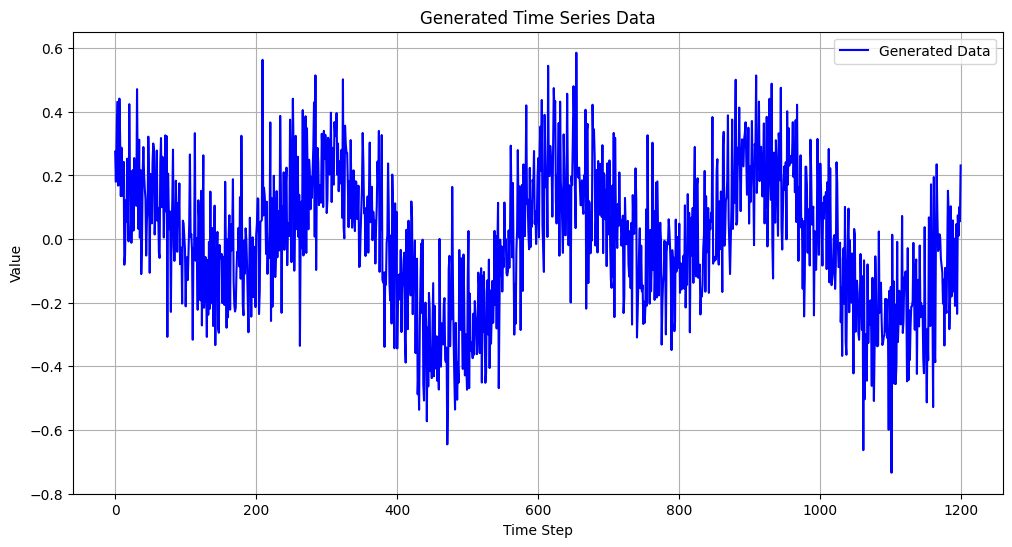

In [4]:
# 데이터 시각화
plt.figure(figsize=(12, 6))
plt.plot(t, y, label='Generated Data', color='blue')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Generated Time Series Data')
plt.legend()
plt.grid(True)
plt.show()

- X축 (가로축): Time Step -> 시간의 흐름 / 0 → 1200까지 순서대로 증가 / 초, 분, 일 같은 실제 시간 단위가 아니라 순서만 중요한 인덱스
- Y축 (세로축): Value -> 각 시간에서의 값 / 사인 + 코사인 + 잡음으로 만든 값

In [5]:
# 데이터 전처리 & 학습/검증 분리
n_train = 900
train_data = y[:n_train] # 처음부터 900번째 데이터까지 학습
val_data = y[n_train:] # 데이터(300개) 검증

시계열 데이터는 **시간의 흐름(순서)이 중요**하기 때문에, 일반적인 데이터처럼 무작위로 섞지(Shuffle) 않고 앞부분은 학습용, 뒷부분은 검증용으로 잘라서 사용

### 시퀀스 데이터 생성 함수 정의

시계열 데이터를 RNN/LSTM에 넣을 수 있는 입력(X)·정답(y) 쌍으로 잘라줘야 함

**create_sequences()**: 연속된 시계열 1차원 데이터를 n_steps 길이의 입력 시퀀스(X)와 그 다음 시점의 값(y)으로 쪼개서 학습용 데이터셋으로 변환하는 함수

**시퀀스(sequence)** 란 순서가 중요한 데이터의 연속. 즉, 앞과 뒤의 위치가 바뀌면 의미가 달라지는 데이터

In [6]:
def create_sequences(data, n_steps):
    X, y = [], []
    for i in range(len(data) - n_steps):
        X.append(data[i:(i + n_steps)])
        y.append(data[i + n_steps])
    return np.array(X), np.array(y)

- n_steps 과거를 몇 개 볼지 

ex) n_steps = 2 -> X 첫 번째 시퀀스: [0.27450712, 0.18022034] / y 정답(바로 다음 값): 0.29899317

! 한 칸 옮겨서 다시 만 (슬라이딩 윈도우 방식)

In [7]:
# 시퀀스 데이터 생성 적용
n_steps = 12
X_train, y_train = create_sequences(train_data, n_steps)
X_val, y_val = create_sequences(val_data, n_steps)

In [8]:
X_train[0]

array([0.27450712, 0.18022034, 0.29899317, 0.43109414, 0.16823627,
       0.16887821, 0.44144005, 0.32015269, 0.13501577, 0.2871406 ,
       0.136484  , 0.13629786])

In [9]:
y_train[0]

0.24253315643420298

### 데이터 차원 재구조화 (Reshape)

Keras의 순환 신경망(RNN, LSTM, GRU 등) 층은 반드시 3차원 텐서(3D Tensor) 형태의 입력 요구

In [10]:
# 입력 데이터 Reshape (samples, timesteps, features) - SimpleRNN은 3차원 입력을 받음
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))

**형태(Shape): (샘플 수, 타임스텝 수, 특성 수)**
- Samples: 데이터 개수 (Batch size)
- Timesteps: 과거를 돌아보는 길이 (n_steps)
- Features: 각 시점의 변수 개수 

# SimpleRNN
순환신경망 / Recurrent Neural Network  
과거의 정보를 짧게 기억하면서 순서가 있는 데이터(시퀀스)를 처리하는 가장 기본적인 순환 신경망(RNN)

In [11]:
# 모델 구축
model = Sequential()
model.add(SimpleRNN(units=32, activation='relu', input_shape=(n_steps, 1)))
model.add(Dense(units=1))

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


- units=32: RNN 내부의 메모리 셀(은닉 노드) 개수 32
- activation='relu': 비선형성을 위해 ReLU 활성화 함
- input_shape=(n_steps, 1): 입력 데이터의 형태 (12, 1)로 정의
- Dense(units=1): RNN의 최종 출력을 받아 하나의 실수값(예측값)으로 변환하는 출력층

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 32)                  │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

 SimpleRNN Params=units×(input_dim+units+1)

 Dense Params=(input units×output units)+bias

- Layer (type): 층의 종류 (SimpleRNN, Dense).
- Output Shape: 각 층을 통과한 데이터의 크기 (Batch size, Units).
- Param: 학습되는 가중치(Weight)와 편향(Bias)의 총개수.

   SimpleRNN: $32 \times (1 + 32 + 1) = 1,088$ 개

   Dense: $32 \times 1 + 1 = 33$ 개 

In [13]:
# 모델 컴파일
optimizer = RMSprop() # 각 가중치마다 학습 속도를 자동으로 조절하는 최적화 알고리즘
model.compile(optimizer=optimizer, loss='mse')

RMSprop은 가중치마다 학습 속도(learning rate)를 자동으로 조절하는 최적화(optimizer) 방법

In [14]:
# 모델 학습
epochs = 100
history = model.fit(X_train, y_train, epochs=epochs, validation_data=(X_val, y_val), verbose=1)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0370 - val_loss: 0.0269
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0283 - val_loss: 0.0264
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0244 - val_loss: 0.0255
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0270 - val_loss: 0.0262
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0251 - val_loss: 0.0256
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0256 - val_loss: 0.0259
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0260 - val_loss: 0.0257
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0237 - val_loss: 0.0296
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0237 - val_loss: 0.0259
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0242 - val_loss: 0.0262
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0228 - val_loss: 0.0259
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

In [15]:
# 모델 평가
loss = model.evaluate(X_val, y_val) # 검증 데이터를 모델에 입력해 예측값을 구하고, 실제 정답과 비교하여 손실 값을 반환
print(f'Validation Loss: {loss:.4f}')

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0292 
Validation Loss: 0.0321


In [16]:
# 예측 결과 시각화 (실제로는 예측 수행 단계)
predicted = model.predict(X_val) # predicted: 모델이 예측한 결과값들이 저장되는 배열

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


### 예측 결과 시각화

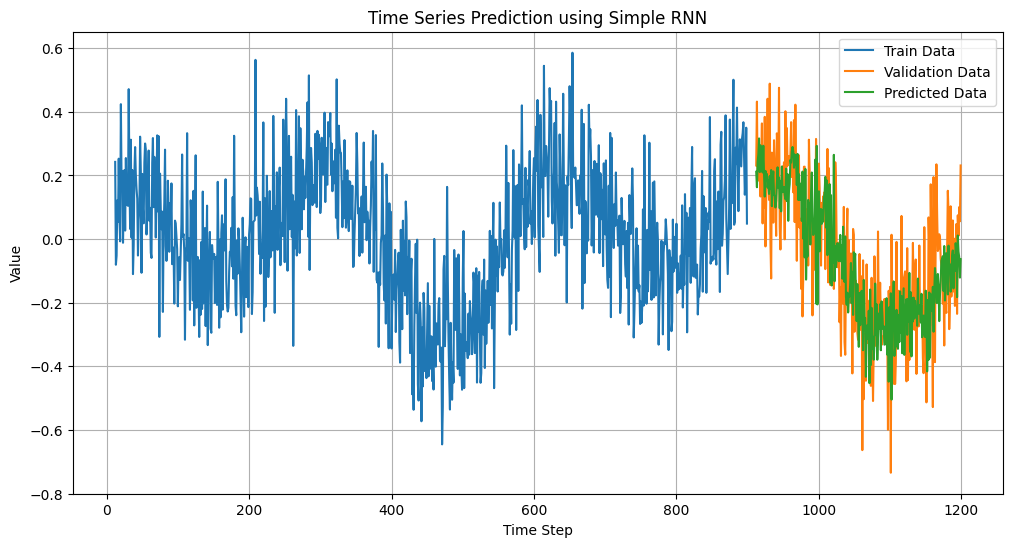

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(np.arange(n_steps, n_train), train_data[n_steps:], label='Train Data')
plt.plot(np.arange(n_train + n_steps, timesteps), val_data[n_steps:], label='Validation Data')
plt.plot(np.arange(n_train + n_steps, timesteps), predicted, label='Predicted Data')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Time Series Prediction using Simple RNN')
plt.legend()
plt.grid(True)
plt.show()

- 모델이 예측하려면 먼저 n_steps만큼 과거를 봐야 해서, 그 구간에는 예측값이 없고 그래서 그래프가 비어 보임

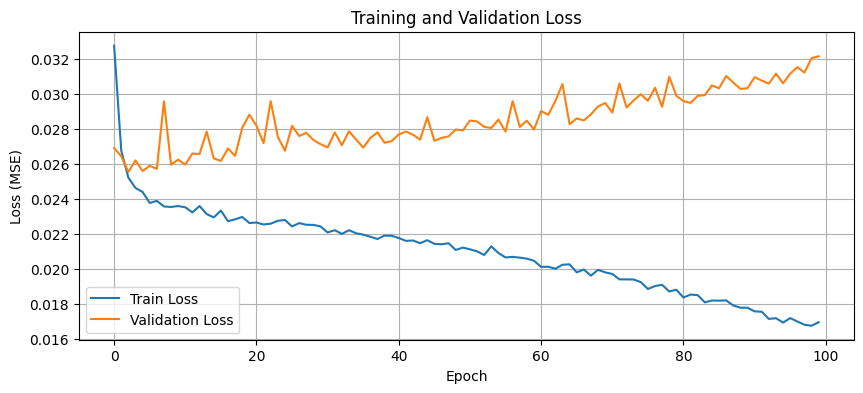

In [19]:
# 학습 곡선 시각화 (손실)
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

- 과적합(Overfitting): Train Loss는 계속 줄어드는데, Validation Loss가 어느 순간 다시 증가하거나 정체

**SimpleRNN의 한계:**

- 과거 정보를 금방 잊음
- 시퀀스가 길어질수록: 기울기 소실 (Vanishing Gradient)
 
장기 패턴 학습 실패

# LSTM (Long Short-Term Memory)
중요한 과거 정보는 오래 기억하고, 필요 없는 정보는 잊도록 설계된 RNN이다.

In [20]:
from tensorflow.keras.layers import LSTM, Dense

In [21]:
# 모델 구축 (LSTM 레이어 사용)
model_lstm = Sequential()
model_lstm.add(LSTM(units=32, activation='relu', input_shape=(n_steps, 1)))
model_lstm.add(Dense(units=1))

In [22]:
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           4,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# 모델 컴파일
optimizer = RMSprop()
model_lstm.compile(optimizer=optimizer, loss='mse')

In [24]:
# 모델 학습
history = model_lstm.fit(X_train, y_train, epochs=100, validation_data=(X_val, y_val), verbose=1)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0350 - val_loss: 0.0298
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0239 - val_loss: 0.0249
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0228 - val_loss: 0.0249
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0238 - val_loss: 0.0250
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0247 - val_loss: 0.0253
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0255 - val_loss: 0.0250
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0250 - val_loss: 0.0251
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0230 - val_loss: 0.0252
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0246 - val_loss: 0.0250
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0226 - val_loss: 0.0250
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0246 - val_loss: 0.0252
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

In [25]:
# 모델 평가
loss = model.evaluate(X_val, y_val)
print(f'Validation Loss (MSE): {loss:.4f}')

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0292 
Validation Loss (MSE): 0.0321


In [26]:
predicted = model_lstm.predict(X_val)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


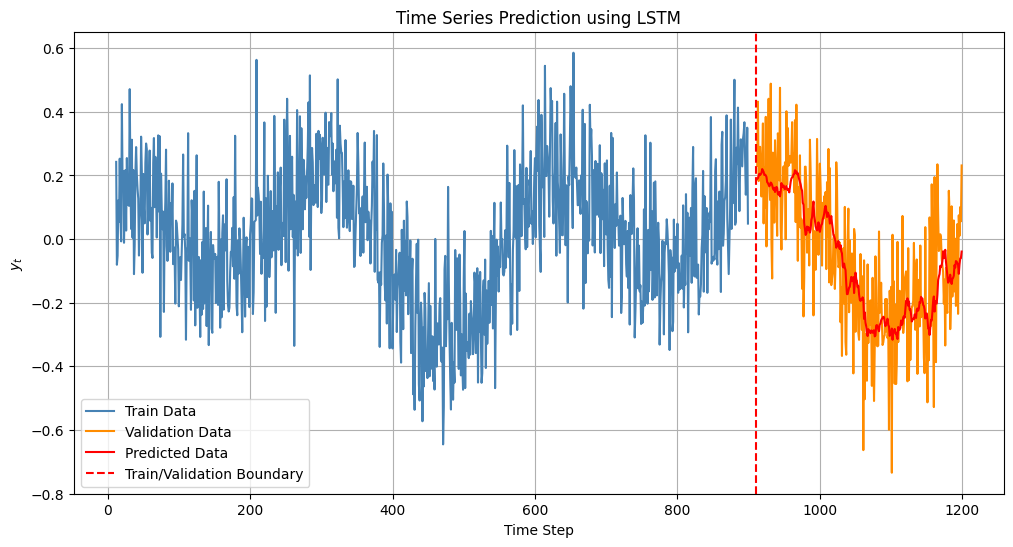

In [27]:
# 예측 결과 시각화
plt.figure(figsize=(12, 6))
plt.plot(np.arange(n_steps, n_train), train_data[n_steps:], label='Train Data', color='steelblue')
plt.plot(np.arange(n_train + n_steps, timesteps), val_data[n_steps:], label='Validation Data', color='darkorange')
plt.plot(np.arange(n_train + n_steps, timesteps), predicted, label='Predicted Data', color='red')
plt.xlabel('Time Step')
plt.ylabel('$y_t$')
plt.title('Time Series Prediction using LSTM')
plt.legend()
plt.grid(True)
plt.axvline(x=n_train + n_steps -1, color='red', linestyle='--', label='Train/Validation Boundary')
plt.legend()
plt.show()

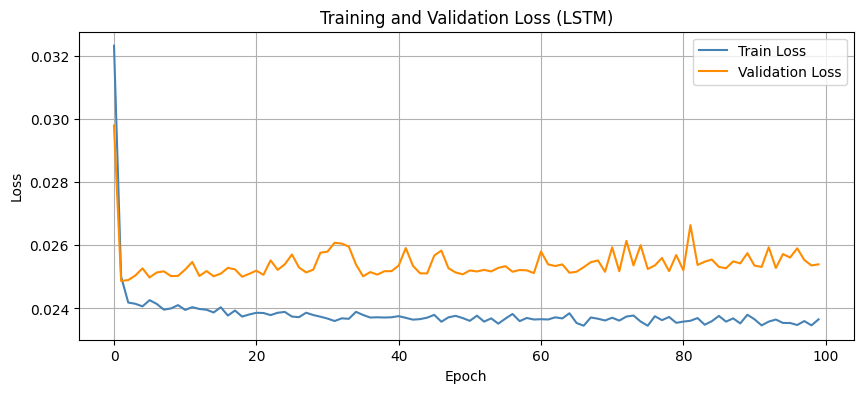

In [28]:
# 학습 곡선 시각화 (손실)
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss', color='steelblue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='darkorange')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss (LSTM)')
plt.legend()
plt.grid(True)
plt.show()

# GRU
LSTM의 성능은 유지하면서 구조를 단순화한 RNN이다.

In [29]:
from tensorflow.keras.layers import GRU

In [30]:
# 모델 구축 (GRU 레이어 사용)
model_gru = Sequential()
model_gru.add(GRU(units=32, activation='relu', input_shape=(n_steps, 1)))
model_gru.add(Dense(units=1))

In [31]:
model_gru.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 32)                  │           3,360 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

**파라미터 수 비교:**

- SimpleRNN: 1,121개  
- LSTM: 4,385개 
- GRU: 3,393개 

In [33]:
# 모델 컴파일
optimizer = RMSprop()
model_gru.compile(optimizer=optimizer, loss='mse')

# 모델 학습
epochs = 100
history = model_gru.fit(X_train, y_train, epochs=100, validation_data=(X_val, y_val), verbose=1)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0335 - val_loss: 0.0304
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0266 - val_loss: 0.0269
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0278 - val_loss: 0.0263
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0248 - val_loss: 0.0262
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0241 - val_loss: 0.0272
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0248 - val_loss: 0.0260
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0246 - val_loss: 0.0259
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0239 - val_loss: 0.0259
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0249 - val_loss: 0.0257
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0230 - val_loss: 0.0255
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0258 - val_loss: 0.0255
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0

In [34]:
# 모델 평가
loss = model_gru.evaluate(X_val, y_val)
print(f'Validation Loss (MSE): {loss:.4f}')

# 훈련 데이터에 대한 예측  
predicted = model_gru.predict(X_val)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0234 
Validation Loss (MSE): 0.0254
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


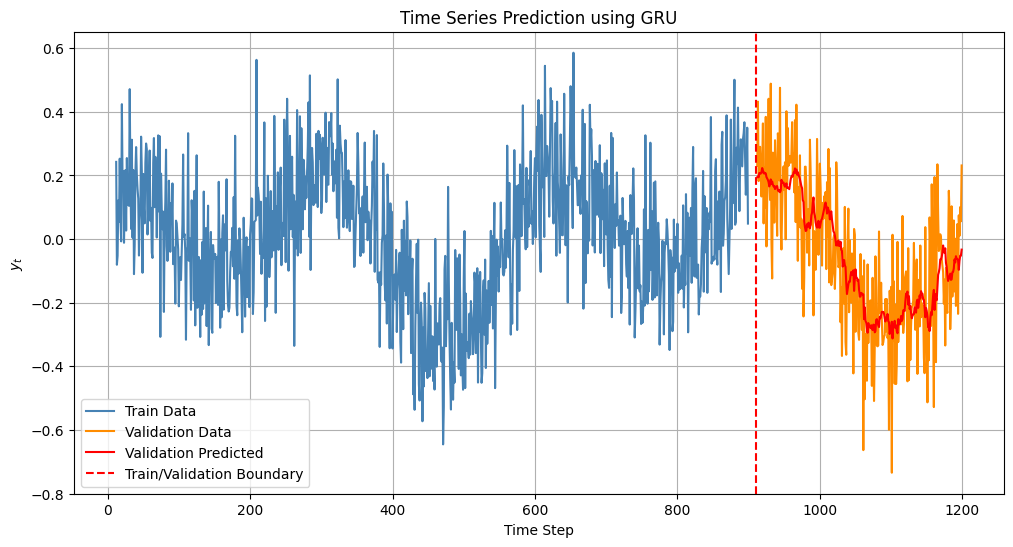

In [35]:
# 예측 결과 시각화 (훈련 데이터 예측 결과 포함)
plt.figure(figsize=(12, 6))
plt.plot(np.arange(n_steps, n_train), train_data[n_steps:], label='Train Data', color='steelblue')
plt.plot(np.arange(n_train + n_steps, timesteps), val_data[n_steps:], label='Validation Data', color='darkorange')
plt.plot(np.arange(n_train + n_steps, timesteps), predicted, label='Validation Predicted', color='red')
plt.xlabel('Time Step')
plt.ylabel('$y_t$')
plt.title('Time Series Prediction using GRU')
plt.legend()
plt.grid(True)
plt.axvline(x=n_train + n_steps - 1, color='red', linestyle='--', label='Train/Validation Boundary')
plt.legend()
plt.show()

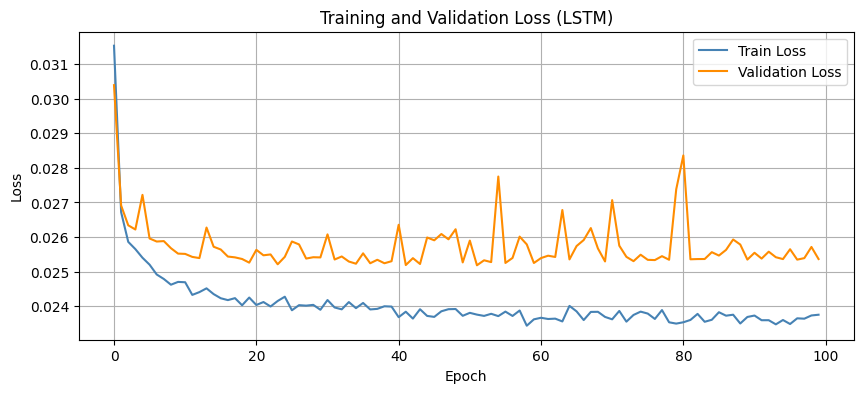

In [36]:
# 학습 곡선 시각화 (손실)  
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss', color='steelblue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='darkorange')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss (LSTM)')
plt.legend()
plt.grid(True)
plt.show()

# 심층 순환 신경망(Deep RNN)
RNN 층을 여러 개 쌓아, 시계열의 복잡한 패턴을 단계적으로 학습하는 모델이다.

In [37]:
model = Sequential()
model.add(SimpleRNN(units=32, activation='relu', input_shape=(n_steps, 1), return_sequences=True))
model.add(SimpleRNN(units=32, activation='relu'))
model.add(Dense(units=1))

**return_sequences=True**: 첫 번째 RNN 층이 마지막 결과값 하나만 다음 층으로 넘기면, 두 번째 RNN 층은 시계열 데이터(순서)를 받을 수 없음. 
따라서 첫 번째 층은 모든 타임스텝의 출력값을 다음 층으로 전달해야 하므로 이 옵션을 반드시 True로 설정해야 함

In [38]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)             │ (None, 12, 32)              │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_2 (SimpleRNN)             │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
optimizer = RMSprop()
model.compile(optimizer=optimizer, loss='mse')

history = model.fit(X_train, y_train, epochs=100, validation_data=(X_val, y_val), verbose=1)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0304 - val_loss: 0.0289
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0231 - val_loss: 0.0259
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0250 - val_loss: 0.0269
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0251 - val_loss: 0.0261
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0246 - val_loss: 0.0265
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0229 - val_loss: 0.0269
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0237 - val_loss: 0.0261
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0236 - val_loss: 0.0266
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0218 - val_loss: 0.0281
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0238 - val_loss: 0.0271
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0212 - val_loss: 0.0275
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

In [40]:
loss = model.evaluate(X_val, y_val)
print(f'Validation Loss (MSE): {loss:.4f}')

predicted = model.predict(X_val)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0411 
Validation Loss (MSE): 0.0457
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


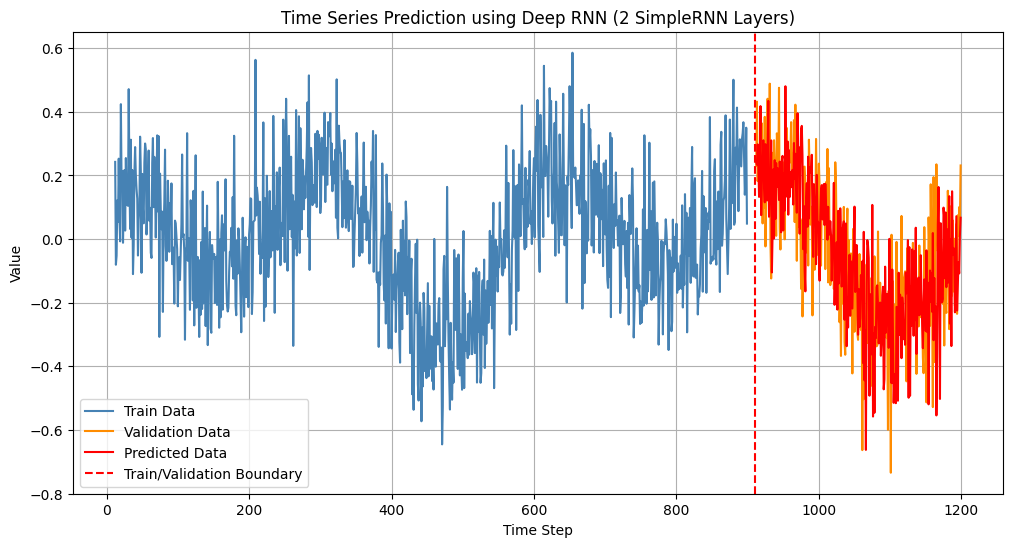

In [41]:
plt.figure(figsize=(12, 6))
plt.plot(np.arange(n_steps, n_train), train_data[n_steps:], label='Train Data', color='steelblue')
plt.plot(np.arange(n_train + n_steps, timesteps), val_data[n_steps:], label='Validation Data', color='darkorange')
plt.plot(np.arange(n_train + n_steps, timesteps), predicted, label='Predicted Data', color='red')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Time Series Prediction using Deep RNN (2 SimpleRNN Layers)')
plt.legend()
plt.grid(True)
plt.axvline(x=n_train + n_steps - 1, color='red', linestyle='--', label='Train/Validation Boundary')
plt.legend()
plt.show()

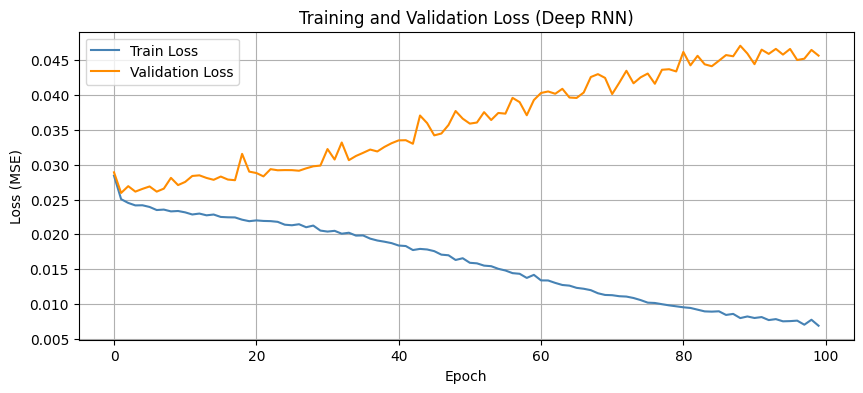

In [42]:
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss', color='steelblue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='darkorange')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss (Deep RNN)')
plt.legend()
plt.grid(True)
plt.show()

SimpleRNN보다도 과대적합이 더 심해짐

# 양방향 RNN(Bidirectional RNN)
시계열(또는 문장)을 앞에서 뒤로만이 아니라, 뒤에서 앞으로도 함께 읽는 RNN이다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Bidirectional
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

### 정상 시계열 데이터 생성

 | 구분 | 이전 데이터 (SimpleRNN, LSTM, GRU) | 지금 데이터 (양방향 RNN) |
|------|-------------------------------------|-----------------------------|
| 상태 | 완전함 (빈 곳 없이 모든 값이 연속됨) | 손상됨 (중간중간 100개의 구멍(NaN)이 뚫림) |
| 목적 | 미래 예측 (Forecasting)<br>과거 패턴을 보고 다음 값을 맞춤 | 결측값 복원 (Imputation)<br>앞뒤 문맥을 보고 빈칸을 채움 |
| 처리 | 있는 그대로 사용 | 빈 곳을 0으로 채우고, 어디가 비었는지 표시(Mask)함 |


In [4]:
# 정상 시계열 데이터 생성
np.random.seed(42)
timesteps = 1200
t = np.arange(timesteps)
noise = np.random.normal(0, 0.15,timesteps)
original_data = 0.2 * np.cos(t / 50) + 0.1 * np.sin(t / 100) + noise

In [5]:
# 결측값 생성
missing_data = original_data.copy() # 원본 데이터 복사
missing_indices = np.random.choice(timesteps, size=100, replace=False)  # 전체 시계열 길이(timesteps) 중에서 # 100개의 서로 다른 인덱스를 무작위 선택
# replace=False → 같은 위치가 중복 선택 X
missing_data[missing_indices] = np.nan

In [6]:
# 시퀀스 데이터 생성 함수 (결측값 마스크 포함)
def create_sequences_with_mask(data, n_steps):
    X, y = [], []
    mask_X = []
    for i in range(n_steps, len(data)):
        X.append(np.where(np.isnan(data[i - n_steps : i]), 0, data[i - n_steps : i])) # 결측값 0으로 채움
        mask_X.append(np.isnan(data[i - n_steps : i]).astype(int)) # 결측 위치를 1, 아니면 0으로 표시
        y.append(data[i])
    return np.array(X), np.array(y), np.array(mask_X)

- X : RNN에 입력될 시퀀스 데이터
- y : 각 시퀀스에 대응되는 정답 값
- mask_X : 결측 위치를 기록한 마스크


원본 데이터:
[1.1, 1.3, NaN, 1.5, 1.6, 1.7]

X:
[1.1, 1.3, 0.0, 1.5, 1.6]

mask_X:
[0,   0,   1,   0,   0]

y:
1.7


In [7]:
n_steps = 30
X, y, mask_X = create_sequences_with_mask(missing_data, n_steps)

In [12]:
# 훈련 및 검증 데이터 분할
X_train, X_val, y_train, y_val, mask_X_train, mask_X_val = train_test_split(
    X, y, mask_X, test_size=0.2, shuffle=False)

In [13]:
# 양방향 RNN 모델 구축 (결측값 보간)
model = Sequential([
    Bidirectional(SimpleRNN(units=32, activation='relu', input_shape=(n_steps, 1))),
    Dense(units=1, activation='linear')
])

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [14]:
model.build(input_shape=(None, n_steps, 1))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)        │ (None, 64)                  │           2,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# 모델 컴파일
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mse')

# 모델 학습 (결측값을 0으로 채운 데이터 사용)
epochs = 100
history = model.fit(X_train, y_train, epochs=epochs, validation_data=(X_val, y_val), verbose=0)

In [25]:
# 결측값 보간
missing_data_filled = missing_data.copy()
for i in range(n_steps, len(missing_data)):
    if np.isnan(missing_data_filled[i]):
        input_sequence = np.where(np.isnan(missing_data_filled[i - n_steps : i]), 0, missing_data_filled[i - n_steps : i]).reshape(1, n_steps, 1)
        predicted_value = model.predict(input_sequence)[0, 0]
        missing_data_filled[i] = predicted_value

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━

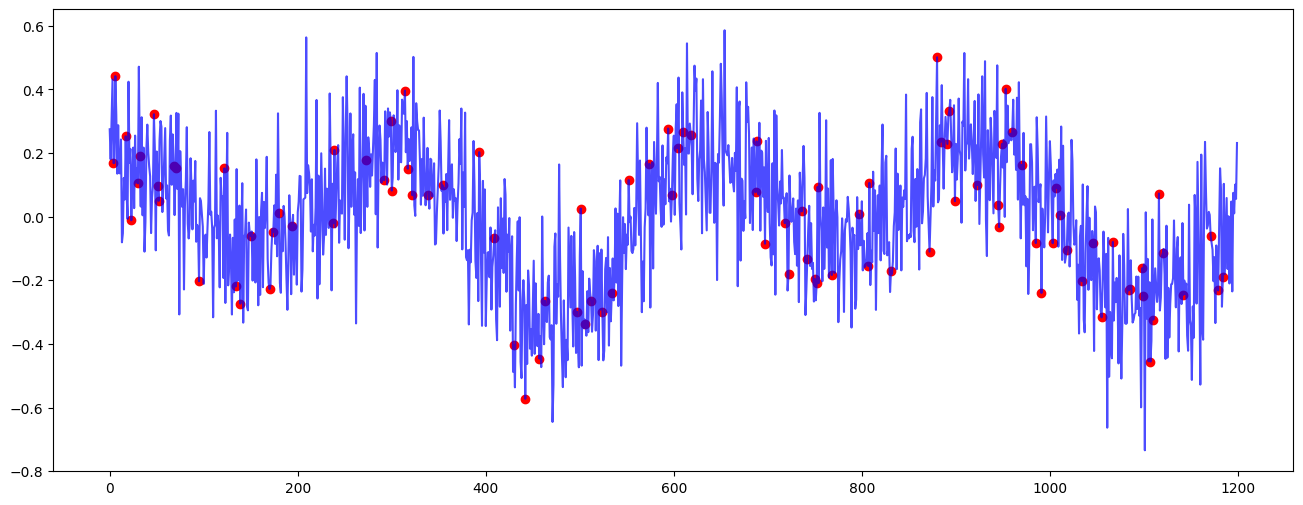

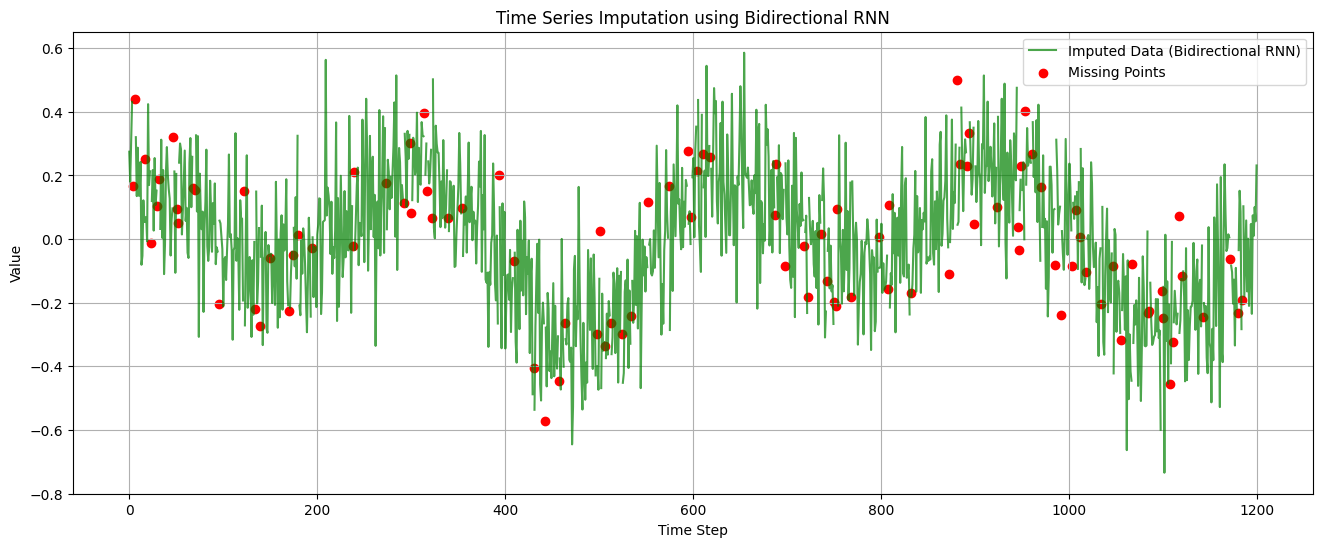

In [26]:
# 결과 시각화
plt.figure(figsize=(16, 6))
plt.plot(t, original_data, label='Original Data', color='blue', alpha=0.7)
plt.scatter(t[missing_indices], original_data[missing_indices], color='red', marker='o', label='Missing Points')
plt.show()
# plt.plot(t, missing_data, label='Missing Data', color='red', alpha=0.7, linestyle='--')
plt.figure(figsize=(16, 6))
plt.plot(t, missing_data_filled, label='Imputed Data (Bidirectional RNN)', color='green', alpha=0.7)
plt.scatter(t[missing_indices], original_data[missing_indices], color='red', marker='o', label='Missing Points')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Time Series Imputation using Bidirectional RNN')
plt.legend()
plt.grid(True)
plt.show()

# 다대다(Many-to-Many)
여러 개의 입력 시퀀스를 받아, 여러 개의 출력 시퀀스를 생성하는 문제

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, TimeDistributed
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [2]:
np.random.seed(42) # 실행할 때마다 동일한 난수가 생성되도록 시드(Seed)
timesteps = 1200 # 전체 시계열 데이터의 길이를 1200개로 설정
t = np.arange(timesteps) # 0부터 1199까지 연속된 시간 인덱스 배열 만듬
noise = np.random.normal(0, 0.15,timesteps) # 평균 0, 표준편차 0.15인 정규분포 난수(잡음)를 생성
y = 0.2 * np.cos(t / 50) + 0.1 * np.sin(t / 100) + noise # 주기가 다른 코사인파와 사인파를 합치고 잡음을 더해, 복합적인 패턴을 가진 시계열 데이터 y를 완성 

In [3]:
# 시퀀스 데이터 생성 (입력과 출력이 동일한 길이)
def create_many_to_many_sequences(data, n_steps):
    X, Y = [], []
    for i in range(len(data) - n_steps):
        X.append(data[i : i + n_steps])
        Y.append(data[i + 1 : i + n_steps + 1]) # 다음 타임스텝 예측
    return np.array(X), np.array(Y)

In [4]:
n_steps = 20
X, Y = create_many_to_many_sequences(y, n_steps)

In [5]:
# 훈련 및 검증 데이터 분할
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, shuffle=False)

In [7]:
# 다대다 SimpleRNN 모델 구축
model = Sequential([
    SimpleRNN(units=32, activation='relu', input_shape=(n_steps, 1), return_sequences=True),
    TimeDistributed(Dense(units=1, activation='linear')) # 각 타임스텝에 대한 예측
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)             │ (None, 20, 32)              │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 20, 1)               │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 모델 컴파일
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mse')

# 모델 학습
epochs = 100
batch_size = 32
history = model.fit(X_train, Y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, Y_val), verbose=1)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0589 - val_loss: 0.0308
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0276 - val_loss: 0.0297
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0266 - val_loss: 0.0293
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0259 - val_loss: 0.0292
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0256 - val_loss: 0.0291
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0250 - val_loss: 0.0289
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0253 - val_loss: 0.0286
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0245 - val_loss: 0.0288
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0245 - val_loss: 0.0290
Epoch 10/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0243 - val_loss: 0.0293
Epoch 11/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0245 - val_loss: 0.0289
Epoch 12/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0

In [9]:
# 예측 수행
predicted = model.predict(X_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step 


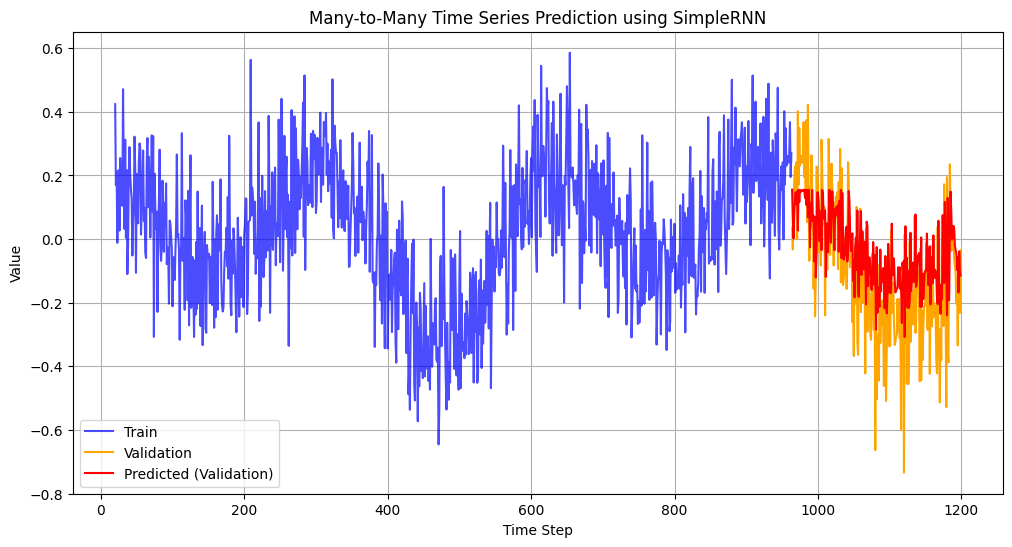

In [10]:
# 결과 시각화
plt.figure(figsize=(12, 6))
plt.plot(np.arange(n_steps, len(y) - len(Y_val)), y[n_steps : len(y) - len(Y_val)], label='Train', color='blue', alpha=0.7)
plt.plot(np.arange(len(y) - len(Y_val), len(y)), Y_val[:, 0], label='Validation', color='orange')
plt.plot(np.arange(len(y) - len(Y_val), len(y)), predicted[:, 0], label='Predicted (Validation)', color='red')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Many-to-Many Time Series Prediction using SimpleRNN')
plt.legend()
plt.grid(True)
plt.show()

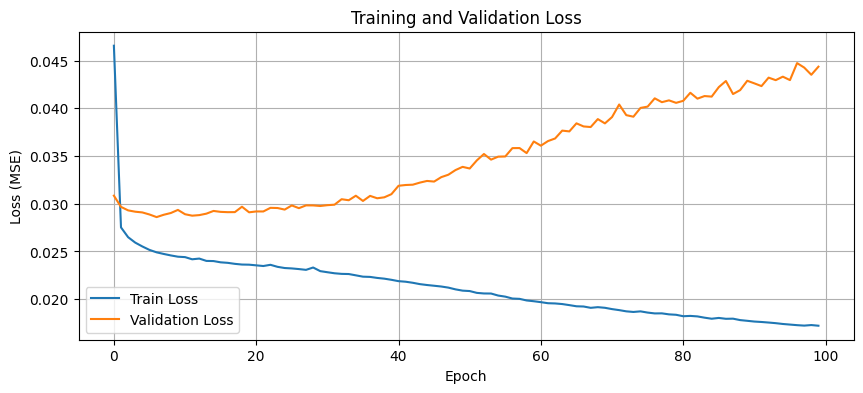

In [11]:
# 학습 곡선 시각화 (손실)
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

# 다대일(Many-to-One): imdb 리뷰
여러 개의 입력이 들어가서 결과는 하나만 나오는 문제

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

https://www.imdb.com/

- imdb: 텐서플로(Keras)에서 기본 제공하는 영화 리뷰 데이터셋
- Embedding: 사람이 사용하는 단어를 컴퓨터가 이해할 수 있는 벡터(숫자들의 나열)로 변환해 주는 핵심 층
- pad_sequences: 문장마다 길이가 다르기 때문에, 모든 리뷰의 길이를 똑같이 맞춰주는 전처리 도구

In [2]:
# IMDb 영화 리뷰 데이터셋 로드
max_words = 10000  # 빈도수 상위 10000개 단어만 사용
maxlen = 200       # 최대 시퀀스 길이
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=max_words)

### 데이터 확인

In [3]:
# 단어 인덱스 가져오기
word_index = imdb.get_word_index() # word_index: {단어: 숫자}
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()]) # {숫자: 단어} 형태로

def decode_review(text):
    return ' '.join([reverse_word_index.get(i - 3, '?') for i in text])

for i in range(10):
    decoded_review = decode_review(x_train[i])
    label = "긍정" if y_train[i] == 1 else "부정"
    print(f"리뷰 {i+1}: {decoded_review[:80]}... (레이블: {label})")

리뷰 1: ? this film was just brilliant casting location scenery story direction everyone... (레이블: 긍정)
리뷰 2: ? big hair big boobs bad music and a giant safety pin these are the words to bes... (레이블: 부정)
리뷰 3: ? this has to be one of the worst films of the 1990s when my friends i were watc... (레이블: 부정)
리뷰 4: ? the ? ? at storytelling the traditional sort many years after the event i can ... (레이블: 긍정)
리뷰 5: ? worst mistake of my life br br i picked this movie up at target for 5 because ... (레이블: 부정)
리뷰 6: ? begins better than it ends funny that the russian submarine crew ? all other a... (레이블: 부정)
리뷰 7: ? lavish production values and solid performances in this straightforward adapti... (레이블: 긍정)
리뷰 8: ? the ? tells the story of the four hamilton siblings teenager francis ? ? twins... (레이블: 부정)
리뷰 9: ? just got out and cannot believe what a brilliant documentary this is rarely do... (레이블: 긍정)
리뷰 10: ? this movie has many problem associated with it that makes it come off like a l... (레이블: 부정)

In [4]:
x_train = pad_sequences(x_train, maxlen=maxlen, padding='post') # padding='pre' 앞쪽(왼쪽)에 패딩(0)을 넣음, Keras 기본값(default).
x_test = pad_sequences(x_test, maxlen=maxlen, padding='post')

- 신경망은 행렬 연산을 수행하기 때문에 모든 입력 데이터의 길이가 같아야 함 !
- **패딩(Padding)이란?**: 길이가 다른 시퀀스들을 “같은 길이”로 맞추기 위해 뒤(또는 앞)에 0을 채워 넣는 것.

예) maxlen = 5

패딩 적용:

- A: [I, love, you, 0, 0]
- B: [I, don’t, like, studying, 0]
- C: [Hi, 0, 0, 0, 0]

In [5]:
# 모델 구축 (Many-to-one LSTM)
embedding_dim = 128
lstm_units = 128

model = Sequential([
    Embedding(max_words, embedding_dim, input_length=maxlen),
    LSTM(lstm_units),
    Dense(1, activation='sigmoid') # 긍정(1) 또는 부정(0) 확률 출력
])

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [6]:
# 모델 컴파일
model.build(input_shape=(None, maxlen))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 200, 128)            │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,411,713 (5.39 MB)

 Trainable params: 1,411,713 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

- Embedding 층 (1,280,000개): $\text{단어 집합 크기} \times \text{임베딩 차원}$
- LSTM 층 (131,584개): $4 \times (\text{units} \times (\text{input} + \text{units}) + \text{bias})$
- Dense 층 (129개): $(\text{입력 유닛} \times \text{출력 유닛}) + \text{bias}$

In [7]:
# 모델 학습
history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.2)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 141ms/step - accuracy: 0.5325 - loss: 0.6869 - val_accuracy: 0.6218 - val_loss: 0.6226
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 135ms/step - accuracy: 0.6554 - loss: 0.6091 - val_accuracy: 0.8166 - val_loss: 0.4364
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 134ms/step - accuracy: 0.6994 - loss: 0.5604 - val_accuracy: 0.5402 - val_loss: 0.6937
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 143ms/step - accuracy: 0.6056 - loss: 0.6324 - val_accuracy: 0.8272 - val_loss: 0.4302
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 142ms/step - accuracy: 0.8702 - loss: 0.3289 - val_accuracy: 0.8686 - val_loss: 0.3183
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 135ms/step - accuracy: 0.9237 - loss: 0.2092 - val_accuracy: 0.8660 - val_loss: 0.3465
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 137ms/step - accuracy: 0.9550 - loss: 0.1386 - val_accuracy: 0.8786 - val_loss: 0.3379
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 137ms/step - accuracy: 0.9718 - loss: 0

In [8]:
# 모델 평가
loss, accuracy = model.evaluate(x_test, y_test)
print(f'테스트 손실: {loss:.4f}')
print(f'테스트 정확도: {accuracy:.4f}')

782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.8570 - loss: 0.5232
테스트 손실: 0.5255
테스트 정확도: 0.8567


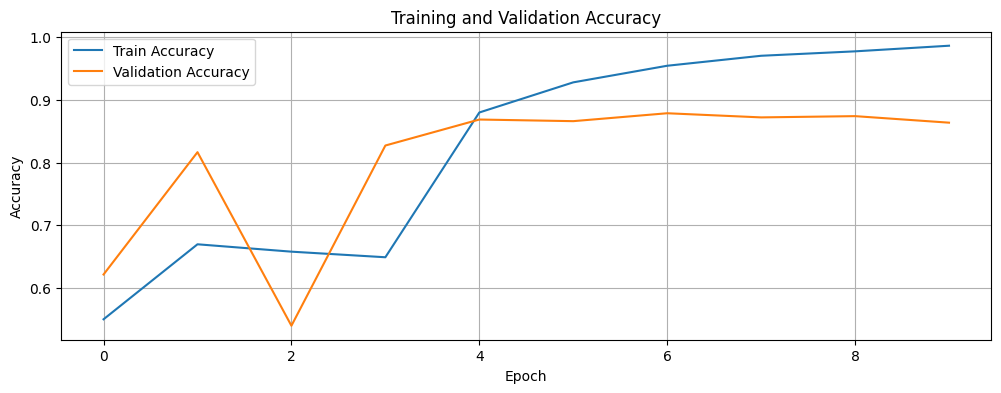

In [9]:
# 학습 곡선 시각화 (정확도)
plt.figure(figsize=(12, 4))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

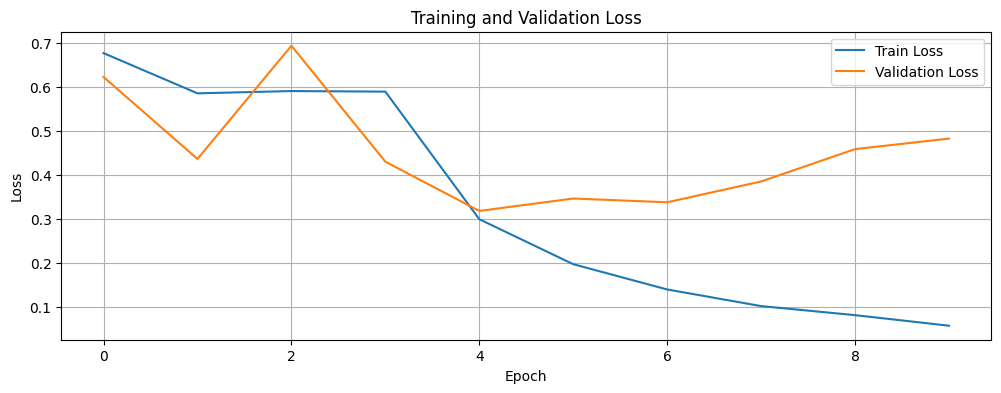

In [10]:
# 학습 곡선 시각화 (손실)
plt.figure(figsize=(12, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# 예측 결과 확인 (처음 몇 개 테스트 샘플)
predictions = model.predict(x_test[:10]) # 테스트 데이터 중 앞 10개 리뷰만 모델에 넣어서
predicted_labels = np.round(predictions).flatten().astype(int) # 예측된 확률을 반올림해서 1 또는 0의 라벨로 변환
original_labels = y_test[:10] # 테스트 데이터의 정답 레이블을 가져옴

word_index = imdb.get_word_index() # MDB에서 단어-숫자 매핑 사전을 가져옴
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()]) # 사전을 숫자 → 단어 꼴로 뒤집음

def decode_review(text):
    return ' '.join([reverse_word_index.get(i - 3, '?') for i in text])

print("\n처음 10개 테스트 리뷰 및 예측 결과:")
for i in range(10):
    review_text = decode_review(x_test[i])
    prediction = "긍정" if predicted_labels[i] == 1 else "부정"
    original = "긍정" if original_labels[i] == 1 else "부정"
    print(f"리뷰: {review_text[:80]}... -> 예측: {prediction}, 실제: {original}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step

처음 10개 테스트 리뷰 및 예측 결과:
리뷰: ? please give this one a miss br br ? ? and the rest of the cast rendered terrib... -> 예측: 부정, 실제: 부정
리뷰: psychological ? it's very interesting that robert altman directed this consideri... -> 예측: 긍정, 실제: 긍정
리뷰: everyone's horror the ? promptly eats the mayor and then goes on a merry rampage... -> 예측: 긍정, 실제: 긍정
리뷰: ? i generally love this type of movie however this time i found myself wanting t... -> 예측: 긍정, 실제: 부정
리뷰: ? like some other people wrote i'm a die hard mario fan and i loved this game br... -> 예측: 긍정, 실제: 긍정
리뷰: ? i'm absolutely disgusted this movie isn't being sold all who love this movie s... -> 예측: 긍정, 실제: 긍정
리뷰: are cleverly ? with long menacing shadows from a sun at the top of the steps the... -> 예측: 부정, 실제: 긍정
리뷰: ? the ? richard ? dog is ? to ? joan fontaine dog however when ? bing crosby arr... -> 예측: 부정, 실제: 부정
리뷰: ? hollywood had a long love affair with bogus ? nights tales but few of these pr... -

**def decode_review()**

이 함수는:

1. 숫자로 된 리뷰 리스트를 받아서
2. i - 3을 해주고
3. 해당 숫자에 맞는 단어를 사전에서 찾아서
4. 단어들을 join(공백으로 연결)해서
5. 사람이 읽을 수 있는 문장으로 바꿔 줌

※ i - 3을 하는 이유:
0,1,2는 특별한 코드라서 실제 단어는 3번부터 시작하기 때문.
- 0 → 패딩(Padding): 비어 있는 자리
- 1 → 문장 시작(Start)
- 2 → 사전에 없는 단어(Unknown word)
- 실제 단어들은 3부터 시작

# 일대다(one-to-many)
Image Captioning: 이미지 1장을 입력하면 그 이미지에 대한 문장을 여러 단어로 출력한다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout, add
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from PIL import Image
import os
from tqdm import tqdm

**멀티 모달(Multi-modal) 학습:** 이미지(CNN 특징)와 텍스트(RNN/LSTM)라는 서로 다른 두 종류의 데이터를 결합(add)하여 학습하는 구조

In [2]:
# 캡션 데이터 로드 및 전처리
def load_captions(filename):
    file = open(filename, 'r')
    doc = file.read()
    file.close()
    mapping = {}
    for line in doc.split('\n'):
        tokens = line.split()
        if len(line) < 2:
            continue
        image_id, image_desc = tokens[0], tokens[1:]
        image_id = image_id.split('.')[0]
        image_desc = ' '.join(image_desc)
        if image_id not in mapping:
            mapping[image_id] = []
        mapping[image_id].append(image_desc)
    return mapping

이미지 캡셔닝 데이터셋(예: Flickr8k, COCO)은 보통 이미지 1장에 5개의 캡션이 달려 있음. 이는 모델이 한 이미지에 대해 다양한 표현(동의어, 문장 구조 변화 등)을 학습할 수 있게 하여 일반화 성능을 높여줌

In [3]:
captions_mapping = load_captions('archive/captions.txt')
all_captions = [desc for key in captions_mapping for desc in captions_mapping[key]]

In [4]:
# 토큰화
tokenizer = Tokenizer(num_words=10000, oov_token="<unk>")
tokenizer.fit_on_texts(all_captions)
word_index = tokenizer.word_index
word_index['<start>'] = len(word_index) + 1
word_index['<end>'] = len(word_index) + 1
index_word = {v: k for k, v in word_index.items()}
vocab_size = len(word_index) + 1
tokenizer.word_index = word_index
tokenizer.index_word = index_word

In [5]:
# 모든 이미지 ID 가져오기
all_img_ids = list(captions_mapping.keys())

In [6]:
train_ids, test_ids = train_test_split(all_img_ids, test_size=0.2, random_state=42) 
# 테스트 세트 비율 20%, 랜덤 시드 고정

print("훈련 이미지 ID 개수:", len(train_ids))
print("테스트 이미지 ID 개수:", len(test_ids))

훈련 이미지 ID 개수: 6473
테스트 이미지 ID 개수: 1619


In [7]:
# 각 ID 목록에 해당하는 캡션 가져오기
train_captions = [captions_mapping[img_id] for img_id in train_ids if img_id in captions_mapping]
test_captions = [captions_mapping[img_id] for img_id in test_ids if img_id in captions_mapping]

print("훈련 캡션 개수:", len(train_captions))
print("테스트 캡션 개수:", len(test_captions))

훈련 캡션 개수: 6473
테스트 캡션 개수: 1619


In [8]:
def create_sequences(tokenizer, captions_mapping, img_features, max_length, image_ids):
    X1, X2, y = [], [], []
    for img_id in tqdm(image_ids):
        if img_id not in captions_mapping:
            continue
        feature_key = img_id + '.jpg'
        if feature_key not in img_features:
            continue
            
        for caption in captions_mapping[img_id]:
            # 텍스트 -> 숫자 변환
            in_seq = tokenizer.texts_to_sequences([caption])[0]
            
            for i in range(1, len(in_seq)):
                # 입력 시퀀스 (과거 단어들)
                in_seq_x = in_seq[:i]
                # 패딩 (입력 X2는 길이를 맞춰줘야 함)
                in_seq_x = pad_sequences([in_seq_x], maxlen=max_length, padding='post')[0]
                
                target_word = in_seq[i]
                
                X1.append(img_features[feature_key])
                X2.append(in_seq_x)
                y.append(to_categorical(target_word, num_classes=vocab_size))
                
    return np.array(X1), np.array(X2), np.array(y)

**지도 학습(Supervised Learning)으로 변환**: 문장 전체를 한 번에 생성하는 것이 아니라, "이미지 + 현재 단어들" 을 보고 "그다음 단어" 하나를 맞추는 과정을 반복 학습.

(입력) 이미지 + start -> (정답) dog

(입력) 이미지 + start dog -> (정답) is

(입력) 이미지 + start dog is -> (정답) running

In [9]:
# 이미지 특징 로드 (미리 추출되었다고 가정)
img_features = np.load('archive/features.npy', allow_pickle=True).item()

- 이미지 1장당 512개의 숫자로 된 리스트 (features.npy)

사진 한 장을 보여주는 대신, 사진을 아주 잘 묘사한 512개의 핵심 키워드 점수를 주는 것과 같음

In [10]:
max_length = 34 
X1_train, X2_train, y_train = create_sequences(tokenizer, captions_mapping, img_features, max_length, train_ids)
X1_test, X2_test, y_test = create_sequences(tokenizer, captions_mapping, img_features, max_length, test_ids)

100%|█████████████████████████████████████████████████████████████████████████████| 1619/1619 [00:02<00:00, 615.95it/s]


In [11]:
# 모델 구축 (합성곱 특징 + 텍스트 입력 병합 모델)
inputs1 = Input(shape=(512,))
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)

inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, 128, mask_zero=True)(inputs2)
se2 = Dropout(0.5)(se1)
se3 = LSTM(256)(se2)

decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

model = Model(inputs=[inputs1, inputs2], outputs=outputs)
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 34)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer (InputLayer)      │ (None, 512)               │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding (Embedding)         │ (None, 34, 128)           │       1,087,616 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 34, 128)           │               0 │ embedding[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, 34)                │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 256)               │         131,328 │ dropout[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm (LSTM)                   │ (None, 256)               │         394,240 │ dropout_1[0][0],           │
│                               │                           │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 256)               │               0 │ dense[0][0], lstm[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 256)               │          65,792 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 8497)              │       2,183,729 │ dense_1[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 3,862,705 (14.74 MB)

 Trainable params: 3,862,705 (14.74 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# 모델 학습 (더 많은 에포크 필요)
epochs = 5
batch_size = 128
history = model.fit([X1_train, X2_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([X1_test, X2_test], y_test))

Epoch 1/5
2485/2485 ━━━━━━━━━━━━━━━━━━━━ 336s 135ms/step - accuracy: 0.3328 - loss: 3.0676 - val_accuracy: 0.3220 - val_loss: 3.7965
Epoch 2/5
2485/2485 ━━━━━━━━━━━━━━━━━━━━ 315s 127ms/step - accuracy: 0.3372 - loss: 3.0073 - val_accuracy: 0.3258 - val_loss: 3.8314
Epoch 3/5
2485/2485 ━━━━━━━━━━━━━━━━━━━━ 299s 120ms/step - accuracy: 0.3426 - loss: 2.9334 - val_accuracy: 0.3245 - val_loss: 3.9135
Epoch 4/5
2485/2485 ━━━━━━━━━━━━━━━━━━━━ 273s 110ms/step - accuracy: 0.3489 - loss: 2.8848 - val_accuracy: 0.3267 - val_loss: 3.9438
Epoch 5/5
2485/2485 ━━━━━━━━━━━━━━━━━━━━ 259s 104ms/step - accuracy: 0.3509 - loss: 2.8453 - val_accuracy: 0.3269 - val_loss: 4.0287


In [23]:
from tensorflow.keras.models import load_model
import pickle
import os

model.save('archive/model_caption.keras')
print("모델 저장 완료: archive/model_caption.keras")

with open('archive/tokenizer.pkl', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)
print("토크나이저 저장 완료: archive/tokenizer.pkl")

모델 저장 완료: archive/model_caption.keras
토크나이저 저장 완료: archive/tokenizer.pkl


In [24]:
loaded_model = load_model('archive/model_caption.keras')

# 토크나이저 로드
with open('archive/tokenizer.pkl', 'rb') as handle:
    loaded_tokenizer = pickle.load(handle)

print("모델 로드 성공")

모델 로드 성공


In [25]:
# 캡션 생성 함수 (Greedy Search)
def generate_caption(model, tokenizer, image_feature, max_length):
    in_text = '<start>'
    for i in range(max_length):
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_length, padding='post')
        
        # 모델 예측
        yhat = model.predict([image_feature, sequence], verbose=0)
        yhat = np.argmax(yhat)
        
        word = tokenizer.index_word.get(yhat)
        
        if word is None or word == '<end>':
            break
        in_text += ' ' + word
    return in_text

[Image ID]: 3139876823_859c7d7c23
[AI 예측]: <start> a mountain in the snow with a backpack in the background and a man in a red jacket and a backpack in the background watch a man in a red shirt and a backpack
[정답]: A downhill skier in black catches a tiny bit of air
--------------------------------------------------


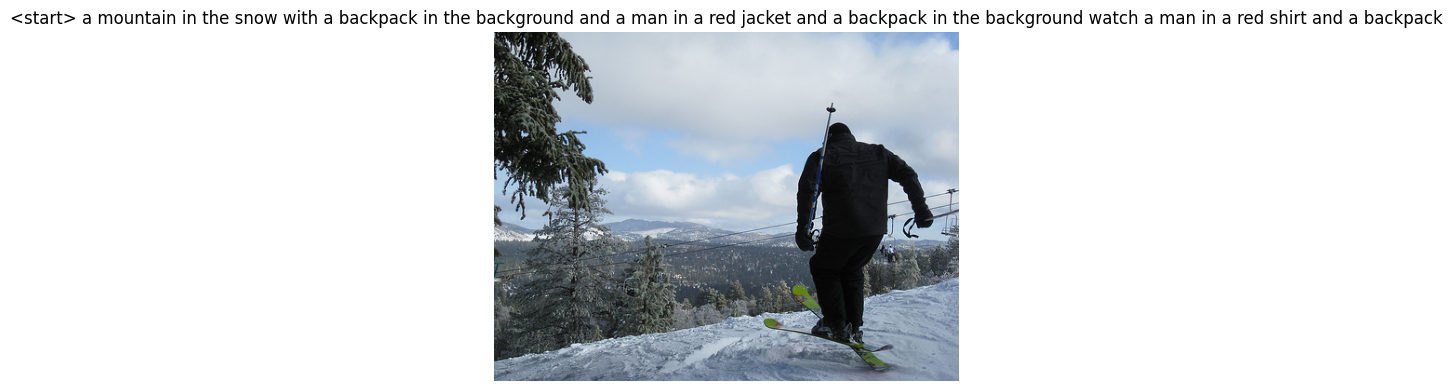

[Image ID]: 3133403457_95dfe11da1
[AI 예측]: <start> a game of people in a red and yellow dress and a blue and white dog in a red shirt and a white and white dog on a red blanket on a wooden bench
[정답]: A child wearing big green fist gloves .
--------------------------------------------------


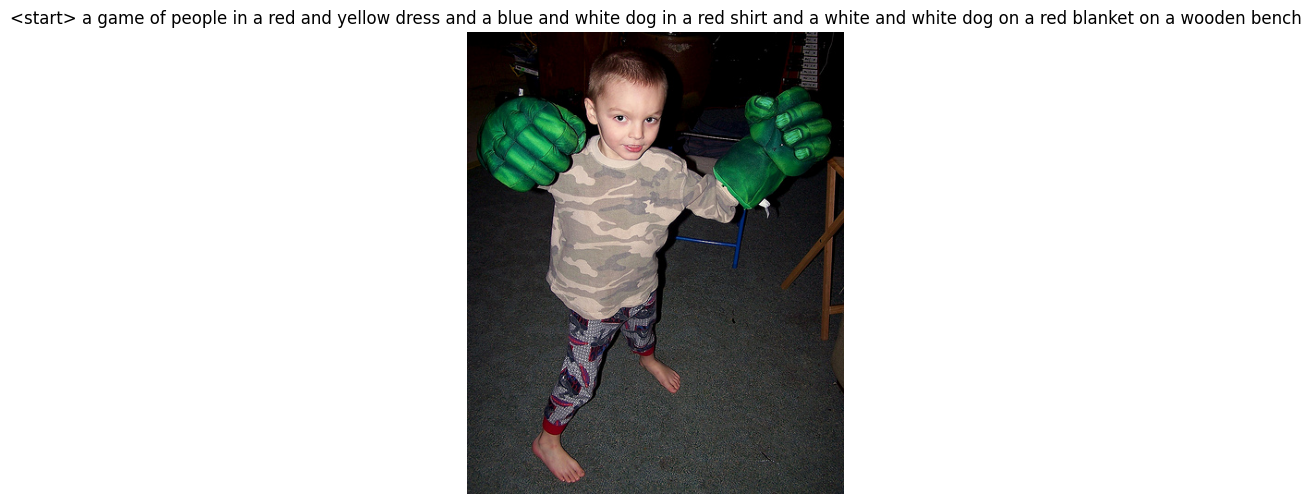

[Image ID]: 244910130_e1f823a28a
[AI 예측]: <start> a rock face with a man in a black shirt and a black hat and a woman in a black shirt and a woman in a black shirt and a woman in a black
[정답]: A dark haired bearded man in glasses and a Hawaiian shirt is sitting on the grass .
--------------------------------------------------


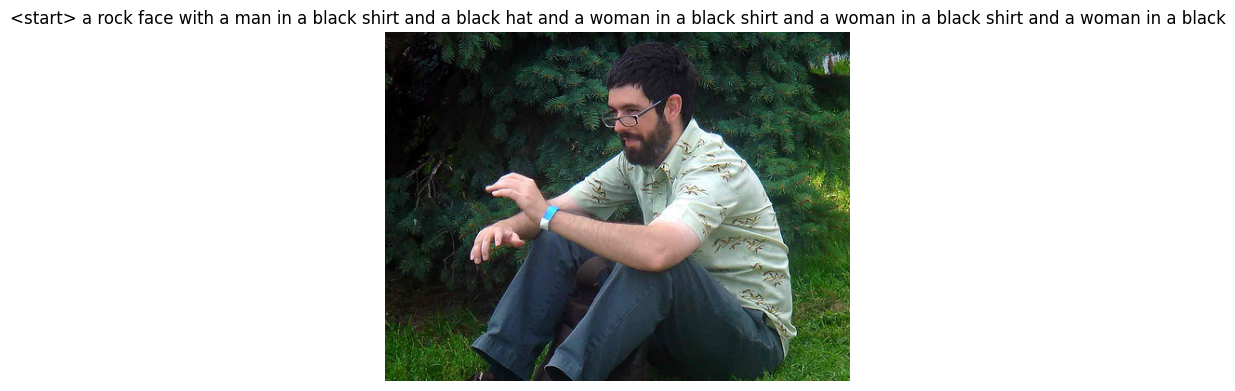

[Image ID]: 2127207912_9298824e66
[AI 예측]: <start> a rock formation in the woods with a rope formation in the background below him climb from the water below him and a man watches him is climbing the water with a rope formation
[정답]: The two people are standing on a rock , holding themselves up against another rock , while looking down
--------------------------------------------------


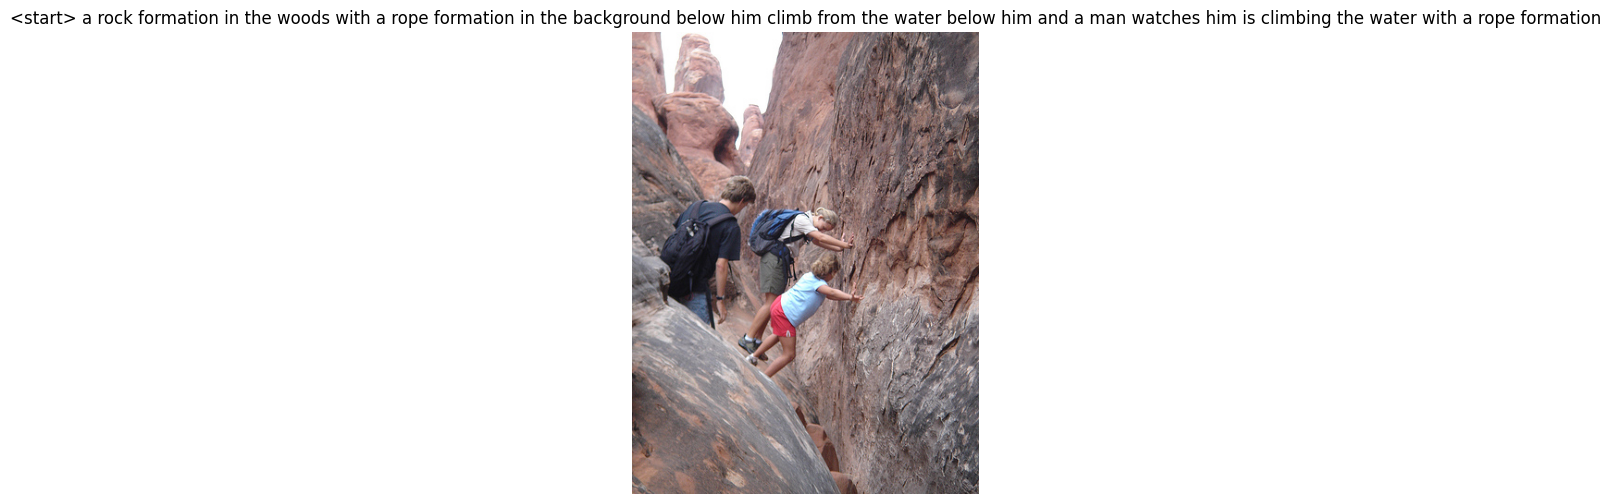

[Image ID]: 1810651611_35aae644fb
[AI 예측]: <start> a game of people in a park with a dog in the background with a red ball in the background with a red ball in the background with a red creature in the background
[정답]: A closeup of a little girl on a swing .
--------------------------------------------------


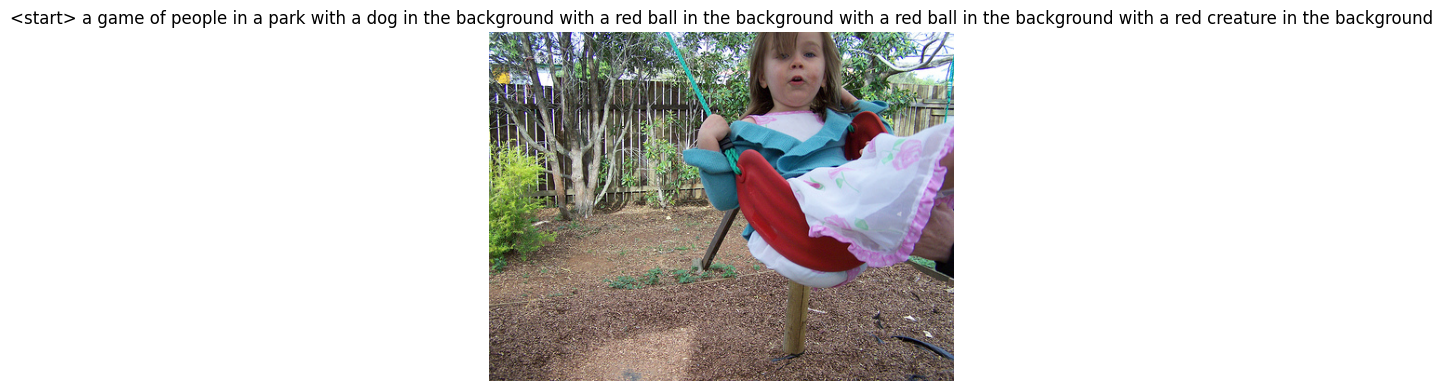

In [26]:
# 테스트
n_examples = 5
test_ids_list = list(test_ids)

for i in range(n_examples):
    img_id = test_ids_list[i]
    img_file = img_id + '.jpg'
    
    if img_file in img_features:
        img_feature = img_features[img_file].reshape(1, 512)
        
        # 불러온 모델로 예측
        predicted_caption = generate_caption(loaded_model, loaded_tokenizer, img_feature, max_length)
        
        print(f"[Image ID]: {img_id}")
        print(f"[AI 예측]: {predicted_caption}")
        try:
            print(f"[정답]: {captions_mapping[img_id][0]}")
        except:
            pass # 정답 데이터가 없는 경우 패스
        print("-" * 50)

        # 이미지 시각화
        try:
            img_path = f'archive/Images/{img_file}'
            img = Image.open(img_path)
            plt.figure(figsize=(6, 6))
            plt.imshow(img)
            plt.axis('off')
            plt.title(predicted_caption, fontsize=12)
            plt.show()
        except Exception as e:
            print(f"이미지 로드 실패: {e}")